# Split-Step LSTM Classifier
Binary classifier: **1 = split step**, **0 = not a split step**.

In [1]:
import json
import pathlib
from typing import List, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

## Configuration

In [ ]:
FEATURE_LANDMARK_NAMES = [
    "left_ankle",    "left_heel",     "left_foot_index",
    "right_ankle",   "right_heel",    "right_foot_index",
    "left_knee",     "right_knee",
    "left_hip",      "right_hip",
    "left_shoulder", "right_shoulder",
    "left_elbow",    "right_elbow",
    "left_wrist",    "right_wrist",
]

N_FEATURES       = len(FEATURE_LANDMARK_NAMES) * 3
MODEL_INPUT_SIZE = N_FEATURES * 2
SEQ_LEN          = 10
THRESHOLD        = 0.9
POS_WEIGHT_CAP   = 5.0

print(f"Landmarks         : {len(FEATURE_LANDMARK_NAMES)}")
print(f"Position features : {N_FEATURES}")
print(f"Model input size  : {MODEL_INPUT_SIZE}  (positions + velocities)")
print(f"Sequence length   : {SEQ_LEN} frames  (~{SEQ_LEN/30:.2f}s)")
print(f"Threshold         : {THRESHOLD}")

Landmarks         : 16
Position features : 48
Model input size  : 96  (positions + velocities)
Sequence length   : 10 frames  (~0.33s)
Threshold         : 0.8


## Load Dataset from CSV

In [4]:
def load_csv_dataset(csv_path: str) -> Tuple[List[np.ndarray], List[int]]:
    df = pd.read_csv(csv_path)
    feature_cols = [f"{name}_world_{ax}" for name in FEATURE_LANDMARK_NAMES for ax in ("x", "y", "z")]
    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    if "label" not in df.columns:
        raise ValueError("'label' column not found — run csv_labeler.py first.")
    X = df[feature_cols].values.astype(np.float32)
    y = df["label"].values.astype(int).tolist()
    return [X[i] for i in range(len(X))], y


CSV_PATH = "assets/csv_files/sideview1_labeled.csv"
feature_frames, label_frames = load_csv_dataset(CSV_PATH)
total, positive = len(label_frames), sum(label_frames)
print(f"Loaded {total} frames — {positive} positive ({positive/total*100:.1f}%)")
print(f"Feature shape: {feature_frames[0].shape}  (expected {N_FEATURES})")

Loaded 15395 frames — 1166 positive (7.6%)
Feature shape: (48,)  (expected 48)


## Build Windows

In [5]:
def build_windows(
    feature_frames: List[np.ndarray],
    label_frames:   List[int],
    seq_len:        int = SEQ_LEN,
) -> Tuple[List[np.ndarray], List[int]]:
    seqs, labels = [], []
    for i in range(seq_len - 1, len(feature_frames)):
        positions  = np.stack(feature_frames[i - seq_len + 1 : i + 1])
        velocities = np.zeros_like(positions)
        velocities[1:] = positions[1:] - positions[:-1]
        seqs.append(np.concatenate([positions, velocities], axis=1))
        labels.append(label_frames[i])
    return seqs, labels


class SplitStepDataset(Dataset):
    def __init__(self, seqs: List[np.ndarray], labels: List[int]):
        self.X = [torch.from_numpy(s) for s in seqs]
        self.y = [torch.tensor(l, dtype=torch.float32) for l in labels]
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

## Model

In [6]:
class SplitStepLSTM(nn.Module):
    def __init__(self, input_size=MODEL_INPUT_SIZE, hidden_size=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_size, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.classifier(out[:, -1, :]).squeeze(1)


print(SplitStepLSTM())

SplitStepLSTM(
  (lstm): LSTM(96, 128, num_layers=2, batch_first=True, dropout=0.3)
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=128, out_features=1, bias=True)
  )
)


## Train / Test Split (75 / 25)

In [7]:
seqs, labels = build_windows(feature_frames, label_frames, SEQ_LEN)
n         = len(seqs)
train_end = int(n * 0.75)

train_seqs,  train_labels = seqs[:train_end],  labels[:train_end]
test_seqs,   test_labels  = seqs[train_end:],  labels[train_end:]

print(f"Total  : {n}  |  Train : {len(train_seqs)} ({sum(train_labels)} pos)  |  Test : {len(test_seqs)} ({sum(test_labels)} pos)")
print(f"Window shape: {seqs[0].shape}  (expected ({SEQ_LEN}, {MODEL_INPUT_SIZE}))")

Total  : 15386  |  Train : 11539 (923 pos)  |  Test : 3847 (243 pos)
Window shape: (10, 96)  (expected (10, 96))


## Feature Normalization

In [8]:
# Fit on training data only — prevents test statistics leaking into training
all_train  = np.stack(train_seqs)           # (n_train, SEQ_LEN, MODEL_INPUT_SIZE)
feat_mean  = all_train.mean(axis=(0, 1))    # (MODEL_INPUT_SIZE,)
feat_std   = all_train.std(axis=(0, 1)) + 1e-8

def normalize(seqs):
    return [(s - feat_mean) / feat_std for s in seqs]

train_seqs_n = normalize(train_seqs)
test_seqs_n  = normalize(test_seqs)

print(f"Feature mean range : {feat_mean.min():.4f} – {feat_mean.max():.4f}")
print(f"Feature std range  : {feat_std.min():.4f} – {feat_std.max():.4f}")
print("Normalization done.")

Feature mean range : -0.4516 – 0.7880
Feature std range  : 0.0011 – 0.2731
Normalization done.


## Training

In [9]:
MODEL_PATH = "split_step_lstm.pt"
EPOCHS     = 40
BATCH_SIZE = 32
LR         = 1e-3
VAL_SPLIT  = 0.15

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Training on: {device}")

val_start = int(len(train_seqs_n) * (1 - VAL_SPLIT))
t_seqs,  t_labels = train_seqs_n[:val_start],  train_labels[:val_start]
v_seqs,  v_labels = train_seqs_n[val_start:],  train_labels[val_start:]

train_dl = DataLoader(SplitStepDataset(t_seqs, t_labels), batch_size=BATCH_SIZE, shuffle=True,  drop_last=True)
val_dl   = DataLoader(SplitStepDataset(v_seqs, v_labels), batch_size=BATCH_SIZE, shuffle=False)

n_pos      = sum(t_labels)
n_neg      = len(t_labels) - n_pos
pw         = min(n_neg / n_pos, POS_WEIGHT_CAP)
pos_weight = torch.tensor([pw], dtype=torch.float32).to(device)
print(f"Train: {len(t_seqs)}  Val: {len(v_seqs)}  pos_weight: {pw:.2f}")

model     = SplitStepLSTM().to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5)

best_val_f1 = 0.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_dl:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    model.eval()
    tp = fp = tn = fn = 0
    with torch.no_grad():
        for X_batch, y_batch in val_dl:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            preds = (torch.sigmoid(model(X_batch)) >= THRESHOLD).float()
            tp += ((preds == 1) & (y_batch == 1)).sum().item()
            fp += ((preds == 1) & (y_batch == 0)).sum().item()
            tn += ((preds == 0) & (y_batch == 0)).sum().item()
            fn += ((preds == 0) & (y_batch == 1)).sum().item()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    scheduler.step(1 - f1)
    print(f"Epoch {epoch:3d}/{EPOCHS}  loss={running_loss/len(train_dl):.4f}  P={precision:.3f}  R={recall:.3f}  F1={f1:.3f}")

    if f1 > best_val_f1:
        best_val_f1 = f1
        torch.save(model.state_dict(), MODEL_PATH)

print(f"\nBest val F1={best_val_f1:.3f} — model saved -> {MODEL_PATH}")

Training on: cpu
Train: 9808  Val: 1731  pos_weight: 5.00
Epoch   1/40  loss=0.3627  P=0.679  R=0.887  F1=0.769
Epoch   2/40  loss=0.2049  P=0.643  R=0.796  F1=0.712
Epoch   3/40  loss=0.1524  P=0.634  R=0.790  F1=0.703
Epoch   4/40  loss=0.1237  P=0.758  R=0.656  F1=0.703
Epoch   5/40  loss=0.1112  P=0.694  R=0.855  F1=0.766
Epoch   6/40  loss=0.1004  P=0.779  R=0.548  F1=0.644
Epoch   7/40  loss=0.0718  P=0.777  R=0.618  F1=0.689
Epoch   8/40  loss=0.0450  P=0.774  R=0.645  F1=0.704
Epoch   9/40  loss=0.0347  P=0.817  R=0.624  F1=0.707
Epoch  10/40  loss=0.0300  P=0.747  R=0.667  F1=0.705
Epoch  11/40  loss=0.0246  P=0.782  R=0.618  F1=0.691
Epoch  12/40  loss=0.0243  P=0.820  R=0.613  F1=0.702
Epoch  13/40  loss=0.0189  P=0.800  R=0.581  F1=0.673
Epoch  14/40  loss=0.0179  P=0.806  R=0.581  F1=0.675
Epoch  15/40  loss=0.0150  P=0.806  R=0.581  F1=0.675
Epoch  16/40  loss=0.0156  P=0.806  R=0.581  F1=0.675
Epoch  17/40  loss=0.0151  P=0.806  R=0.581  F1=0.675
Epoch  18/40  loss=0.014

## Test Evaluation

In [11]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
model.eval()

all_preds, all_labels_list = [], []
with torch.no_grad():
    for X_batch, y_batch in DataLoader(SplitStepDataset(test_seqs_n, test_labels), batch_size=BATCH_SIZE):
        preds = (torch.sigmoid(model(X_batch.to(device))).cpu() >= THRESHOLD).float()
        all_preds.extend(preds.tolist())
        all_labels_list.extend(y_batch.tolist())

P = torch.tensor(all_preds)
G = torch.tensor(all_labels_list)
tp = ((P==1)&(G==1)).sum().item()
fp = ((P==1)&(G==0)).sum().item()
tn = ((P==0)&(G==0)).sum().item()
fn = ((P==0)&(G==1)).sum().item()

precision = tp/(tp+fp) if (tp+fp)>0 else 0.0
recall    = tp/(tp+fn) if (tp+fn)>0 else 0.0
f1        = 2*precision*recall/(precision+recall) if (precision+recall)>0 else 0.0

print(f"Test set ({len(G)} windows)")
print(f"  Accuracy  : {(tp+tn)/len(G):.3f}")
print(f"  Precision : {precision:.3f}")
print(f"  Recall    : {recall:.3f}")
print(f"  F1        : {f1:.3f}")
print(f"  TP={tp}  FP={fp}  TN={tn}  FN={fn}")

Test set (3847 windows)
  Accuracy  : 0.955
  Precision : 0.639
  Recall    : 0.642
  F1        : 0.641
  TP=156  FP=88  TN=3516  FN=87


## Prediction vs Ground Truth Plot

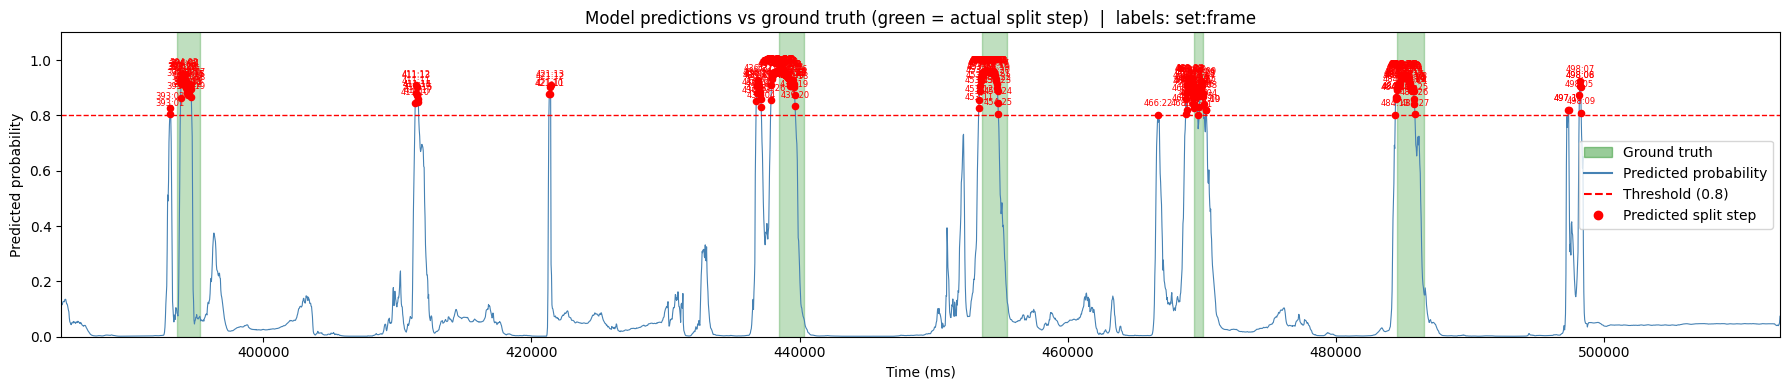

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

SAMPLE_MS = 100 / 3  # 33.33ms per frame

model.eval()
all_probs = []
with torch.no_grad():
    for X_batch, _ in DataLoader(SplitStepDataset(test_seqs_n, test_labels), batch_size=BATCH_SIZE):
        all_probs.extend(torch.sigmoid(model(X_batch.to(device))).cpu().tolist())

all_probs = np.array(all_probs)
all_gt    = np.array(test_labels)

start_frame = train_end + SEQ_LEN - 1
timestamps  = (start_frame + np.arange(len(all_probs))) * SAMPLE_MS  # ms

def frame_label(ts_ms):
    frame    = round(ts_ms / SAMPLE_MS)
    sets     = frame // 30
    remaining = frame % 30
    return f"{sets}:{remaining:02d}"

fig, ax = plt.subplots(figsize=(18, 4))

in_block = False
for i, gt in enumerate(all_gt):
    if gt == 1 and not in_block:
        block_start, in_block = timestamps[i], True
    elif gt == 0 and in_block:
        ax.axvspan(block_start, timestamps[i], color="green", alpha=0.25)
        in_block = False
if in_block:
    ax.axvspan(block_start, timestamps[-1], color="green", alpha=0.25)

ax.plot(timestamps, all_probs, color="steelblue", linewidth=0.8)
ax.axhline(THRESHOLD, color="red", linestyle="--", linewidth=1)

mask    = all_probs >= THRESHOLD
pred_ts = timestamps[mask]
pred_p  = all_probs[mask]
ax.scatter(pred_ts, pred_p, color="red", s=20, zorder=5)
for ts, p in zip(pred_ts, pred_p):
    ax.annotate(frame_label(ts), xy=(ts, p), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=6, color="red")

ax.set_xlim(timestamps[0], timestamps[-1])
ax.set_ylim(0, 1.1)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Predicted probability")
ax.set_title("Model predictions vs ground truth (green = actual split step)  |  labels: set:frame")
ax.legend(handles=[
    mpatches.Patch(color="green", alpha=0.4, label="Ground truth"),
    plt.Line2D([0],[0], color="steelblue", label="Predicted probability"),
    plt.Line2D([0],[0], color="red", linestyle="--", label=f"Threshold ({THRESHOLD})"),
    plt.Line2D([0],[0], marker="o", color="red", linestyle="None", label="Predicted split step"),
])
plt.tight_layout()
plt.show()

## Inference — Predictor

In [37]:
class Predictor:
    """Rolling-window predictor. Feed one position frame at a time."""

    def __init__(self, model_path="split_step_lstm.pt", seq_len=SEQ_LEN,
                 threshold=THRESHOLD, device=None):
        if device is None:
            device = "cuda" if torch.cuda.is_available() else "cpu"
        self.device, self.seq_len, self.threshold = device, seq_len, threshold
        self.buffer: List[np.ndarray] = []
        self.prev_frame = None

        self.model = SplitStepLSTM().to(device)
        self.model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
        self.model.eval()

    def update(self, features: np.ndarray) -> Tuple[bool, float]:
        velocity = features - self.prev_frame if self.prev_frame is not None else np.zeros_like(features)
        self.prev_frame = features
        frame = (np.concatenate([features, velocity]) - feat_mean) / feat_std
        self.buffer.append(frame)
        if len(self.buffer) > self.seq_len:
            self.buffer.pop(0)
        if len(self.buffer) < self.seq_len:
            return False, 0.0
        x = torch.from_numpy(np.stack(self.buffer)).unsqueeze(0).to(self.device)
        with torch.no_grad():
            prob = torch.sigmoid(self.model(x)).item()
        return prob >= self.threshold, prob

## Persistence (JSON)

In [38]:
def save_dataset(feature_frames, label_frames, path):
    pathlib.Path(path).write_text(json.dumps(
        {"features": [f.tolist() for f in feature_frames], "labels": label_frames}))

def load_dataset(path):
    payload = json.loads(pathlib.Path(path).read_text())
    return [np.array(f, dtype=np.float32) for f in payload["features"]], payload["labels"]